<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_096_lstm_gru_real_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 96/365 — LSTM vs GRU on a Real Dataset

Yesterday we trained a vanilla RNN on real sunspot data.

Today we compare three sequence models on the same task:

- RNN
- LSTM
- GRU

Task:

**Use the previous 12 years of sunspot activity to predict the next year.**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from statsmodels.datasets import sunspots


## 1. Load the real dataset

In [2]:
data = sunspots.load_pandas().data.copy()

years = data["YEAR"].astype(int).values

values = (
    data["SUNACTIVITY"]
    .astype(np.float32)
    .values
    .reshape(-1,1)
)

print(data.head())
print("Rows:", len(data))


     YEAR  SUNACTIVITY
0  1700.0          5.0
1  1701.0         11.0
2  1702.0         16.0
3  1703.0         23.0
4  1704.0         36.0
Rows: 309


## 2. Chronological split and scaling

In [3]:
split = int(len(values) * 0.8)

scaler = MinMaxScaler()
scaler.fit(values[:split])

scaled = scaler.transform(values)


## 3. Create 12-step sequences

In [4]:
sequence_length = 12

X, y = [], []

for i in range(len(scaled) - sequence_length):
    X.append(scaled[i:i+sequence_length])
    y.append(scaled[i+sequence_length])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

target_indices = np.arange(
    sequence_length,
    len(scaled)
)

train_mask = target_indices < split
test_mask = target_indices >= split

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]


In [5]:
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train),
        torch.tensor(y_train)
    ),
    batch_size=32,
    shuffle=True
)


## 4. Build a reusable RNN/LSTM/GRU model

In [6]:
class SequenceModel(nn.Module):

    def __init__(self, kind):
        super().__init__()

        hidden_size = 16

        if kind == "rnn":
            self.sequence = nn.RNN(
                1,
                hidden_size,
                batch_first=True
            )

        elif kind == "lstm":
            self.sequence = nn.LSTM(
                1,
                hidden_size,
                batch_first=True
            )

        else:
            self.sequence = nn.GRU(
                1,
                hidden_size,
                batch_first=True
            )

        self.output = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        sequence_output, _ = (
            self.sequence(x)
        )

        last_step = (
            sequence_output[:, -1, :]
        )

        return self.output(last_step)


## 5. Train helper

In [7]:
def train_model(
    kind,
    epochs=60
):

    torch.manual_seed(42)

    model = SequenceModel(kind)

    loss_fn = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01
    )

    losses = []

    for epoch in range(epochs):

        model.train()

        total_loss = 0
        total_samples = 0

        for xb, yb in train_loader:

            optimizer.zero_grad()

            prediction = model(xb)

            loss = loss_fn(
                prediction,
                yb
            )

            loss.backward()

            optimizer.step()

            total_loss += (
                loss.item() * len(xb)
            )

            total_samples += len(xb)

        losses.append(
            total_loss / total_samples
        )

    model.eval()

    with torch.no_grad():

        pred_scaled = model(
            torch.tensor(X_test)
        ).numpy()

    prediction = scaler.inverse_transform(
        pred_scaled
    )

    actual = scaler.inverse_transform(
        y_test
    )

    mae = mean_absolute_error(
        actual.ravel(),
        prediction.ravel()
    )

    return model, losses, prediction, mae


## 6. Train all three models

In [8]:
results = {}

for kind in [
    "rnn",
    "lstm",
    "gru"
]:

    model, losses, prediction, mae = (
        train_model(kind)
    )

    results[kind] = {
        "model": model,
        "losses": losses,
        "prediction": prediction,
        "mae": mae
    }

    print(
        kind.upper(),
        "MAE:",
        round(mae,2)
    )


RNN MAE: 15.65
LSTM MAE: 13.66
GRU MAE: 16.16


## 7. Compare test performance

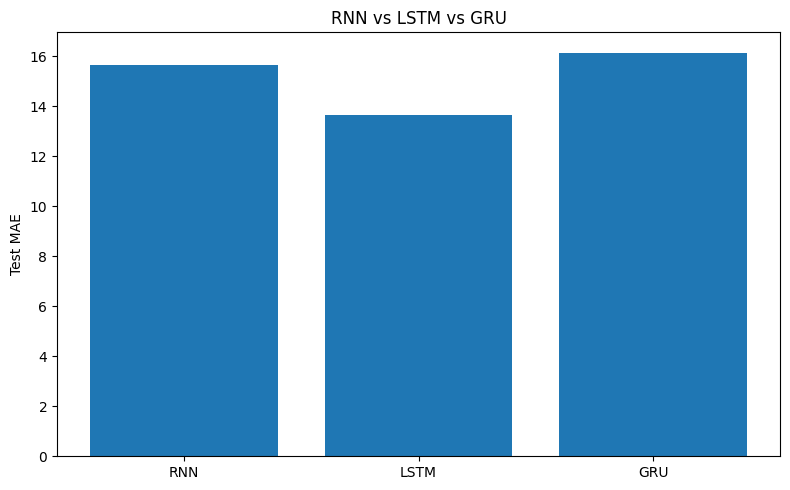

In [9]:
names = [
    "RNN",
    "LSTM",
    "GRU"
]

maes = [
    results["rnn"]["mae"],
    results["lstm"]["mae"],
    results["gru"]["mae"]
]

plt.figure(figsize=(8,5))

plt.bar(
    names,
    maes
)

plt.ylabel("Test MAE")
plt.title("RNN vs LSTM vs GRU")
plt.tight_layout()
plt.show()


## 8. Compare predictions

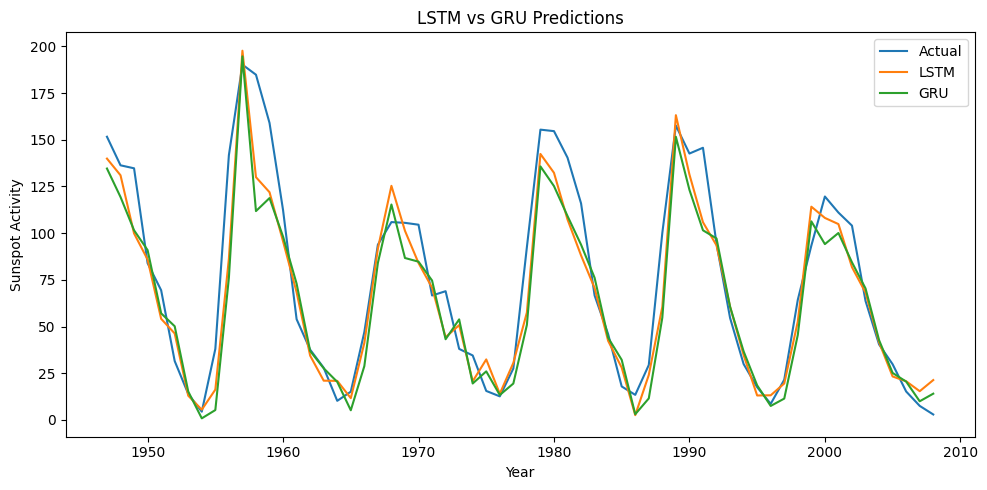

In [10]:
actual = scaler.inverse_transform(
    y_test
)

test_years = years[
    target_indices[test_mask]
]

plt.figure(figsize=(10,5))

plt.plot(
    test_years,
    actual.ravel(),
    label="Actual"
)

plt.plot(
    test_years,
    results["lstm"]["prediction"].ravel(),
    label="LSTM"
)

plt.plot(
    test_years,
    results["gru"]["prediction"].ravel(),
    label="GRU"
)

plt.xlabel("Year")
plt.ylabel("Sunspot Activity")
plt.title("LSTM vs GRU Predictions")
plt.legend()
plt.tight_layout()
plt.show()


## 9. What makes LSTM different?

LSTM adds a memory cell controlled by gates:

- Forget gate
- Input gate
- Output gate

These gates help decide what to keep, what to forget and what to expose as output.


## 10. What makes GRU different?

GRU simplifies the idea.

It mainly uses:

- Update gate
- Reset gate

It usually has fewer parameters than LSTM.


## Simple takeaway

A vanilla RNN carries information forward.

LSTM and GRU add gates that control that information more carefully.

> **RNN remembers. LSTM and GRU learn what is worth remembering.**


## References

- LSTM:
  https://www.bioinf.jku.at/publications/older/2604.pdf

- GRU:
  https://arxiv.org/abs/1406.1078

- PyTorch LSTM:
  https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html

- PyTorch GRU:
  https://pytorch.org/docs/stable/generated/torch.nn.GRU.html
